# 1. Install Libraries

In [ ]:
!pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn

# 2. Import Libraries

In [1]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
import pandas as pd
import numpy as np

# 3. Import Dataset

In [2]:
df = pd.read_csv("credit.csv")

# 4. Dataset Preprocessing

In [3]:
categorical_cols = ['Gender', 'Marital Status', 'CardColour', 'CardType', 'Domain']
df[categorical_cols] = df[categorical_cols].apply(lambda col: LabelEncoder().fit_transform(col))


X = df.drop(columns=['Outcome'])
y = df['Outcome']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 5. Apply SMOTE

In [4]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedShuffleSplit

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y)


# 6. Split Dataset

In [5]:
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
for train_idx, temp_idx in sss.split(X_resampled, y_resampled):
    X_train, X_temp = X_resampled[train_idx], X_resampled[temp_idx]
    y_train, y_temp = y_resampled.iloc[train_idx], y_resampled.iloc[temp_idx]

sss_val = StratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
for val_idx, test_idx in sss_val.split(X_temp, y_temp):
    X_val, X_test = X_temp[val_idx], X_temp[test_idx]
    y_val, y_test = y_temp.iloc[val_idx], y_temp.iloc[test_idx]


# 7. Train Model

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

# 8. Evaluate Model

In [9]:
from sklearn.metrics import roc_auc_score
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("AUC: ", round(roc_auc_score(y_test, y_proba), 3))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Test Accuracy: 0.91
AUC:  0.968
Confusion Matrix:
 [[4024   82]
 [ 653 3452]]
Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.98      0.92      4106
           1       0.98      0.84      0.90      4105

    accuracy                           0.91      8211
   macro avg       0.92      0.91      0.91      8211
weighted avg       0.92      0.91      0.91      8211



# 9. Plot Confusion Matrix

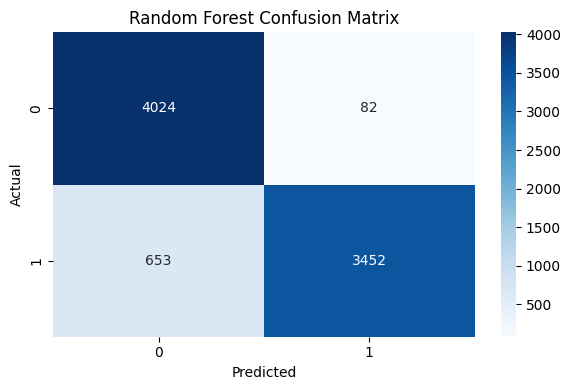

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# 10. Plot ROC Curve

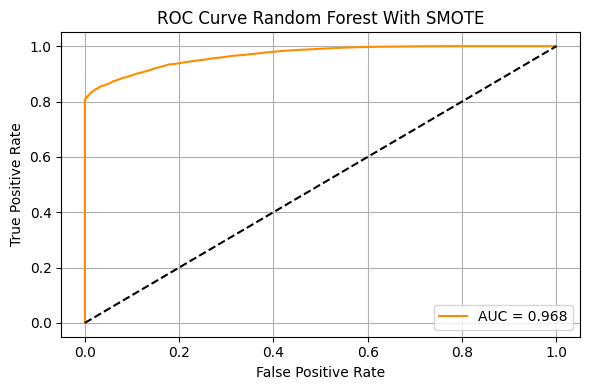

In [14]:
from sklearn.metrics import roc_curve

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Plot ROC curve
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"AUC = {round(roc_auc_score(y_test, y_proba), 3)}", color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='black')  # Diagonal line
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Random Forest With SMOTE")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()